In [17]:
import numpy as np
import netCDF4 as nc

import matplotlib.pyplot as plt
from pathlib import Path
import xarray as xr

In [2]:
file = Path("~/SouthEnglandPrecipitation.nc").expanduser()
dataset = nc.Dataset(str(file), mode="r")

In [5]:
print(dataset.variables.keys())

dict_keys(['number', 'valid_time', 'latitude', 'longitude', 'expver', 'cp', 'lsp'])


In [6]:
dataset.variables["latitude"][:].shape

(10,)

dict_keys(['number', 'valid_time', 'latitude', 'longitude', 'expver', 'cp', 'lsp'])
(1042, 10, 12)


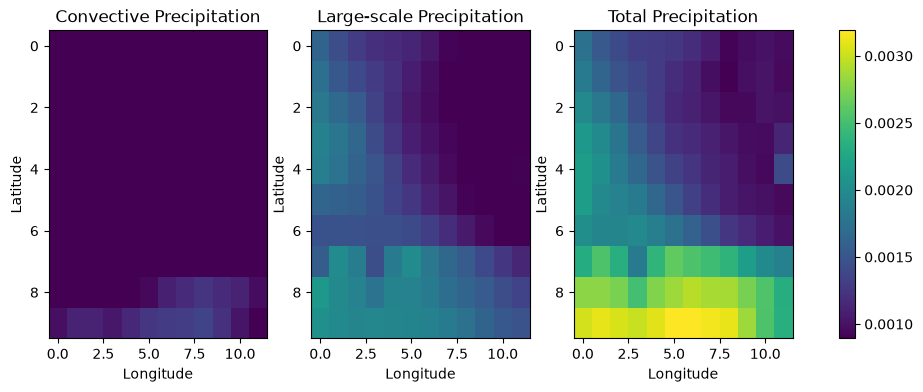

In [16]:
with nc.Dataset(str(file), "r") as ds:
    print(ds.variables.keys())

    lat = ds.variables["latitude"][:]
    lon = ds.variables["longitude"][:]
    convp = ds.variables["cp"][:]
    lsp = ds.variables["lsp"][:]
    tot = convp + lsp
    assert tot.shape == lsp.shape
    print(tot.shape)

    fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(12, 4))

    heatmaps = [convp[0], lsp[0], tot[0]]
    titles = ["Convective Precipitation", "Large-scale Precipitation", "Total Precipitation"]
    vmin, vmax = min(tot[0].flatten()), max(tot[0].flatten())

    for ax, hm, title in zip(axes, heatmaps, titles):
        im = ax.imshow(hm, aspect='auto', vmin=vmin, vmax=vmax)
        ax.set_title(title)
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")

    fig.colorbar(im, ax=axes, orientation='vertical')
    #plt.tight_layout()
    plt.show()

In [ ]:
times